<a href="https://colab.research.google.com/github/tikakukeko/Studi_Kasus_Dan_Implementasi_Kode_Atikah_Putri_Utami_G1A024027/blob/main/Studi_Kasus_Attributing_direct_drivers_to_deforestation_alerts_with_satellite_imagery_and_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Studi Kasus Lengkap: Pemanfaatan AI dan Citra Satelit untuk Pemantauan Deforestasi Hutan Tropis
### Informatics Practitioner Lecture Series 2026



## 1. Latar Belakang

Hutan tropis membantu menyimpan karbon, mengatur siklus air, menjaga keanekaragaman hayati, dan mendukung kehidupan masyarakat. Perubahan penggunaan lahan, penebangan, pertambangan, pembangunan jalan, dan kebakaran dapat mengganggu fungsi tersebut.

Pemantauan berbasis satelit dapat membantu mengamati kawasan yang luas secara berkala. AI dapat digunakan untuk mengklasifikasikan pola perubahan berdasarkan fitur citra, tetapi hasilnya perlu divalidasi dengan data lapangan.

## 2. Rumusan Masalah

1. Mengapa pemantauan hutan membutuhkan data satelit yang konsisten?
2. Apa perbedaan informasi dari Sentinel-1 dan Sentinel-2?
3. Bagaimana model klasifikasi dapat digunakan untuk mengidentifikasi penyebab langsung perubahan hutan?
4. Bagaimana hasil model dievaluasi dan apa keterbatasannya?
5. Mengapa data lapangan tetap diperlukan untuk validasi?

## 3. Tujuan

- Memahami peran citra satelit dalam pemantauan hutan.
- Mengenali perbedaan citra radar Sentinel-1 dan citra optik Sentinel-2.
- Memahami konsep CNN untuk klasifikasi citra.
- Menyimulasikan alur klasifikasi penyebab perubahan tutupan hutan.
- Menggunakan confusion matrix, precision, recall, dan F1-score untuk membaca hasil klasifikasi.
- Mengidentifikasi keterbatasan teknis dan pentingnya validasi lapangan.

## 4. Dasar Teori

### 4.1 Sentinel-1
Sentinel-1 menggunakan radar sehingga pengamatan lebih konsisten pada kondisi berawan. Sinyal radar memberikan informasi mengenai karakteristik permukaan dan struktur vegetasi, tetapi interpretasinya berbeda dari citra optik.

### 4.2 Sentinel-2
Sentinel-2 menggunakan sensor optik yang merekam pantulan pada beberapa kanal spektral. Data ini dapat membantu mempelajari kondisi vegetasi, tetapi kualitas pengamatan dapat terganggu oleh awan dan bayangan.

### 4.3 Penggabungan data
Menggabungkan fitur radar dan optik dapat memberikan informasi yang saling melengkapi. Namun, data perlu disejajarkan secara spasial dan temporal, diperiksa kualitasnya, serta ditangani bila terdapat nilai hilang atau awan.

### 4.4 CNN
Convolutional Neural Network (CNN) merupakan jenis Deep Learning yang dapat mempelajari pola spasial dari citra melalui operasi konvolusi. CNN biasanya membutuhkan data berlabel yang cukup, pengaturan pelatihan yang tepat, dan evaluasi pada wilayah atau waktu yang tidak digunakan saat training.

## 5. Kelas Penyebab Perubahan Hutan

Berdasarkan konteks resume, kategori contoh mencakup:
- Pertanian skala kecil.
- Pertanian skala besar.
- Pembangunan jalan.
- Penebangan kayu selektif.
- Pertambangan.
- Kebakaran hutan.
- Gangguan alami, misalnya banjir atau pohon tumbang akibat angin.

Kategori ini adalah contoh label klasifikasi. Dalam proyek nyata, definisi kelas harus dibuat operasional dan konsisten, serta disertai pedoman anotasi agar penilai berbeda tidak memberi label secara sembarangan.

## 6. Rancangan Alur Kerja

1. **Menentukan wilayah dan periode:** tetapkan batas kawasan serta waktu pengamatan.
2. **Mengumpulkan data:** memperoleh citra Sentinel-1, Sentinel-2, dan label rujukan yang dapat diverifikasi.
3. **Prapemrosesan:** menangani awan pada citra optik, memeriksa kualitas radar, menyelaraskan resolusi dan proyeksi, serta menyamakan periode.
4. **Membangun sampel:** memotong citra menjadi patch dan menghubungkannya dengan label yang tervalidasi.
5. **Membagi data:** pisahkan data training, validation, dan testing berdasarkan lokasi atau waktu untuk mengurangi kebocoran spasial.
6. **Melatih model:** gunakan CNN atau model pembanding yang sesuai.
7. **Mengevaluasi:** periksa confusion matrix, precision, recall, F1-score per kelas, serta performa antarwilayah.
8. **Memvalidasi lapangan:** bandingkan hasil klasifikasi dengan bukti lapangan atau interpretasi ahli.
9. **Menyajikan hasil:** petakan prediksi dengan keterangan ketidakpastian dan tanggal data.

## 7. Data dan Fitur yang Diperlukan

Contoh fitur yang mungkin digunakan dalam proyek nyata:
- Kanal optik Sentinel-2, seperti kanal merah, hijau, biru, inframerah dekat, dan inframerah gelombang pendek.
- Fitur radar Sentinel-1, seperti polarisasi VV dan VH bila tersedia pada produk yang digunakan.
- Indeks vegetasi yang dihitung dari kanal optik setelah prapemrosesan yang sesuai.
- Informasi waktu, lokasi, tutupan lahan sebelumnya, dan label rujukan.

Pilihan fitur bergantung pada pertanyaan penelitian, karakteristik wilayah, ketersediaan data, dan metode prapemrosesan. Notebook ini tidak mengunduh atau mengolah citra satelit asli.

## 8. Demonstrasi Edukatif dengan Data Sintetis


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## 9. Membuat Dataset Simulasi

In [2]:
classes = [
    "Pertanian skala kecil",
    "Pertanian skala besar",
    "Pembangunan jalan",
    "Penebangan selektif",
    "Pertambangan",
    "Kebakaran hutan",
    "Gangguan alami"
]

n_per_class = 120
rows = []

# Fitur-fitur berikut adalah indeks sintetis untuk demonstrasi, bukan band satelit sebenarnya.
for class_id, label in enumerate(classes):
    for _ in range(n_per_class):
        rows.append({
            "optical_vegetation_index": np.clip(rng.normal([0.62, 0.48, 0.30, 0.55, 0.22, 0.18, 0.42][class_id], 0.12), -1, 1),
            "radar_change_index": rng.normal([0.25, 0.35, 0.70, 0.45, 0.80, 0.75, 0.65][class_id], 0.20),
            "bare_soil_index": np.clip(rng.normal([0.25, 0.58, 0.75, 0.30, 0.85, 0.65, 0.35][class_id], 0.18), -1, 1),
            "texture_change_index": rng.normal([0.30, 0.40, 0.80, 0.60, 0.75, 0.55, 0.70][class_id], 0.22),
            "cause": label
        })

df = pd.DataFrame(rows)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
df.head()

,optical_vegetation_index,radar_change_index,bare_soil_index,texture_change_index,cause
0,0.360541,0.617786,0.740195,0.784515,Kebakaran hutan
1,0.361145,0.729029,-0.144898,0.691436,Gangguan alami
2,0.497180,0.285855,0.289599,0.599021,Pertanian skala kecil
3,0.166971,0.763340,0.734043,0.879515,Pertambangan
4,0.427847,0.091173,0.329135,0.415321,Pertanian skala kecil


## 10. Pemeriksaan Data



In [3]:
print("Ukuran data:", df.shape)
print("\nTipe data:")
print(df.dtypes)
print("\nNilai kosong:")
print(df.isna().sum())
print("\nDistribusi kelas:")
print(df["cause"].value_counts())
display(df.describe())

Ukuran data: (840, 5)

Tipe data:
optical_vegetation_index    float64
radar_change_index          float64
bare_soil_index             float64
texture_change_index        float64
cause                        object
dtype: object

Nilai kosong:
optical_vegetation_index    0
radar_change_index          0
bare_soil_index             0
texture_change_index        0
cause                       0
dtype: int64

Distribusi kelas:
cause
Kebakaran hutan          120
Gangguan alami           120
Pertanian skala kecil    120
Pertambangan             120
Pembangunan jalan        120
Penebangan selektif      120
Pertanian skala besar    120
Name: count, dtype: int64


,optical_vegetation_index,radar_change_index,bare_soil_index,texture_change_index
count,840.000000,840.000000,840.000000,840.000000
mean,0.392706,0.560616,0.524412,0.582804
std,0.191239,0.284501,0.274814,0.282317
min,-0.104663,-0.379683,-0.165819,-0.244731
25%,0.254807,0.358402,0.312497,0.384429
50%,0.389979,0.587609,0.531155,0.583786
75%,0.535789,0.769294,0.740524,0.792542
max,0.968608,1.371488,1.000000,1.290541


### Visualisasi distribusi kelas

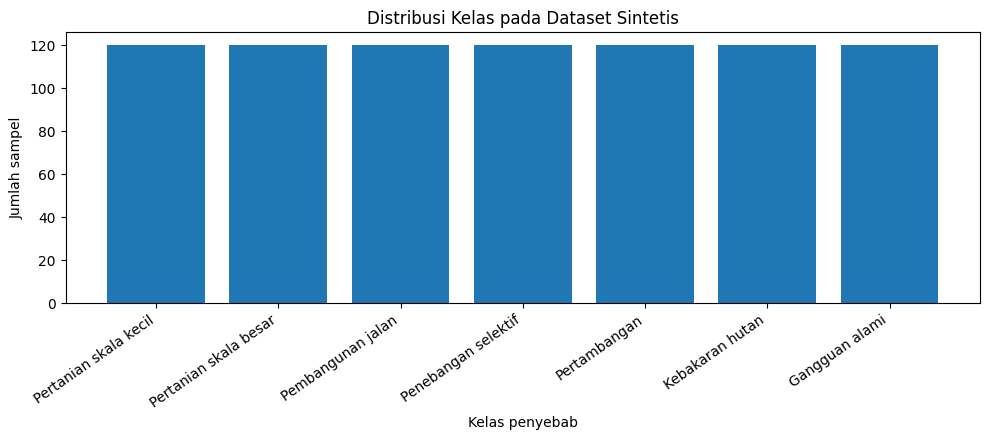

In [4]:
class_counts = df["cause"].value_counts().reindex(classes)
plt.figure(figsize=(10, 4.5))
plt.bar(class_counts.index, class_counts.values)
plt.title("Distribusi Kelas pada Dataset Sintetis")
plt.xlabel("Kelas penyebab")
plt.ylabel("Jumlah sampel")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 11. Membagi Data Training dan Testing


In [5]:
feature_cols = [
    "optical_vegetation_index",
    "radar_change_index",
    "bare_soil_index",
    "texture_change_index"
]
X = df[feature_cols]
y = df["cause"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (630, 4)
Testing : (210, 4)


## 12. Melatih Model Baseline



In [6]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Akurasi:", round(accuracy_score(y_test, y_pred), 3))

Akurasi: 0.571


## 13. Evaluasi Klasifikasi



                       precision    recall  f1-score   support

       Gangguan alami       0.62      0.70      0.66        30
      Kebakaran hutan       0.39      0.37      0.38        30
    Pembangunan jalan       0.54      0.50      0.52        30
  Penebangan selektif       0.47      0.57      0.52        30
         Pertambangan       0.52      0.50      0.51        30
Pertanian skala besar       0.83      0.67      0.74        30
Pertanian skala kecil       0.68      0.70      0.69        30

             accuracy                           0.57       210
            macro avg       0.58      0.57      0.57       210
         weighted avg       0.58      0.57      0.57       210



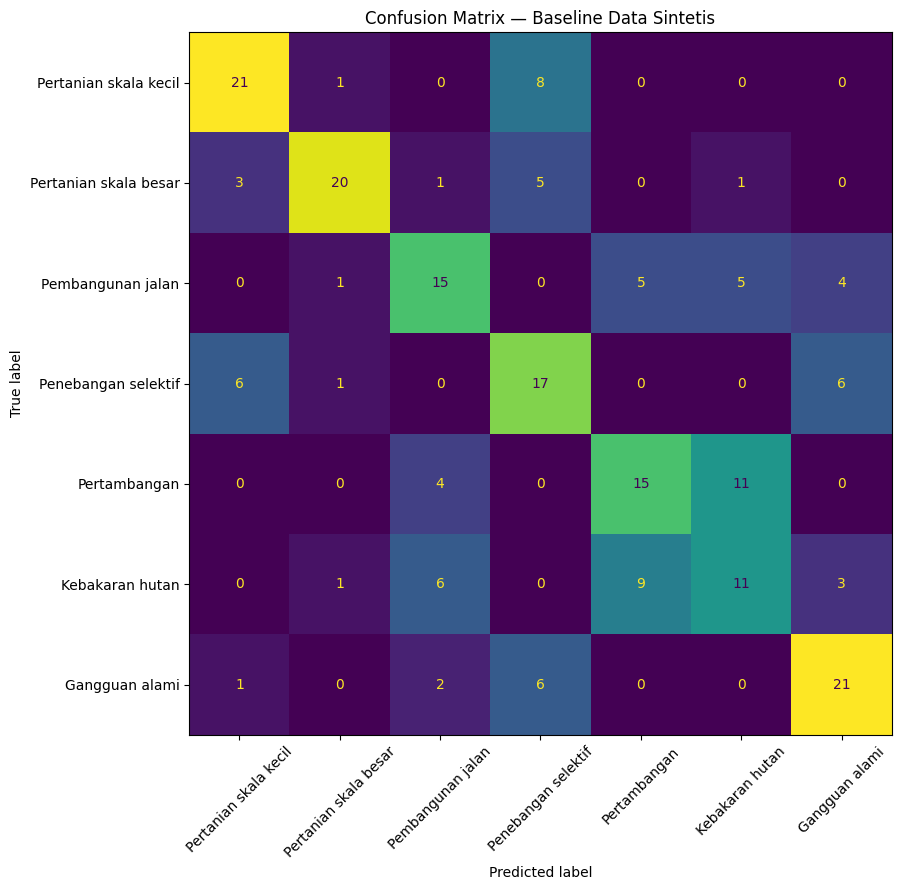

In [7]:
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
fig, ax = plt.subplots(figsize=(11, 9))
disp.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Confusion Matrix — Baseline Data Sintetis")
plt.tight_layout()
plt.show()

## 14. Prediksi Satu Sampel Baru


In [8]:
sample = pd.DataFrame([{
    "optical_vegetation_index": 0.25,
    "radar_change_index": 0.72,
    "bare_soil_index": 0.78,
    "texture_change_index": 0.70
}])

predicted_class = model.predict(sample)[0]
probabilities = model.predict_proba(sample)[0]
print("Prediksi kelas sintetis:", predicted_class)

prob_table = pd.DataFrame({
    "kelas": model.classes_,
    "probabilitas_model": probabilities
}).sort_values("probabilitas_model", ascending=False)
display(prob_table)

Prediksi kelas sintetis: Pertambangan


,kelas,probabilitas_model
4,Pertambangan,0.585
2,Pembangunan jalan,0.210
1,Kebakaran hutan,0.185
5,Pertanian skala besar,0.015
0,Gangguan alami,0.005
3,Penebangan selektif,0.000
6,Pertanian skala kecil,0.000


## 15. CNN dan Model Pembanding

CNN dapat mempelajari pola spasial dari patch citra, sedangkan model tabular seperti Random Forest menggunakan fitur yang sudah diringkas. Perbandingan yang adil perlu memakai data, pembagian train-test, dan metrik evaluasi yang setara.

Pertimbangkan:
- Apakah CNN benar-benar meningkatkan performa dibandingkan baseline?
- Berapa banyak label terverifikasi yang diperlukan?
- Berapa waktu pelatihan dan kebutuhan komputasinya?
- Apakah peningkatan performa konsisten di wilayah dan waktu berbeda?
- Apakah kesalahan model berdampak besar pada keputusan konservasi?

Jangan menyimpulkan CNN selalu lebih baik hanya karena termasuk Deep Learning.

## 16. Tantangan dan Sumber Kesalahan

- **Awan dan bayangan:** dapat mengurangi kualitas pengamatan optik.
- **Keselarasan data:** citra radar dan optik perlu cocok dalam lokasi, resolusi, dan waktu.
- **Kelas yang mirip:** pola kebakaran, banjir, penebangan, dan gangguan lain dapat tumpang tindih.
- **Label yang tidak konsisten:** label salah atau definisi kelas yang tidak jelas akan mengganggu pelatihan.
- **Ketidakseimbangan kelas:** beberapa penyebab mungkin jauh lebih jarang dibanding yang lain.
- **Kebocoran spasial:** sampel yang berdekatan dapat membuat hasil uji tampak terlalu optimistis.
- **Perubahan wilayah:** model yang dilatih di satu wilayah mungkin tidak bekerja sama baiknya di wilayah lain.
- **Keterbatasan pembaruan:** interval pembaruan dan ketersediaan citra memengaruhi waktu deteksi.

## 17. Validasi Lapangan dan Interpretasi

Hasil klasifikasi perlu diperiksa melalui data lapangan, citra resolusi lebih tinggi bila tersedia, catatan otoritatif, atau interpretasi ahli. Validasi perlu mencakup sampel dari berbagai kelas dan wilayah, bukan hanya lokasi yang mudah dijangkau.

Peta prediksi sebaiknya menunjukkan tanggal data, kelas hasil, tingkat keyakinan bila tersedia, dan batasan interpretasi. Klasifikasi AI adalah indikasi untuk pemeriksaan lebih lanjut, bukan bukti otomatis terjadinya pelanggaran atau penyebab pasti perubahan hutan.

## 18. Transparansi, Kebijakan, dan Etika

Pemantauan satelit dapat membantu transparansi dan mendukung prioritas pemeriksaan. Namun:
- Hindari menuduh pelaku atau menetapkan penyebab pasti hanya dari prediksi model.
- Jelaskan sumber data, metode, waktu pengamatan, dan ketidakpastian.
- Lindungi informasi sensitif yang dapat membahayakan masyarakat atau kawasan tertentu.
- Pastikan hasil digunakan bersama verifikasi yang layak dan proses kebijakan yang adil.
- Dokumentasikan kesalahan model, terutama jika hasil memengaruhi keputusan penegakan hukum atau pengelolaan lahan.

## 19. Pertanyaan Diskusi

1. Apa perbedaan utama Sentinel-1 dan Sentinel-2?
2. Mengapa menggabungkan radar dan citra optik dapat bermanfaat?
3. Mengapa klasifikasi penyebab perubahan hutan lebih sulit daripada sekadar mendeteksi perubahan tutupan?
4. Apa fungsi CNN dalam klasifikasi citra?
5. Mengapa model perlu dibandingkan dengan metode yang lebih sederhana?
6. Apa arti precision, recall, dan F1-score dalam kasus ini?
7. Mengapa pemisahan data berdasarkan lokasi atau waktu penting?
8. Mengapa validasi lapangan tetap diperlukan?
9. Bagaimana hasil prediksi dapat membantu kebijakan tanpa menjadi satu-satunya dasar keputusan?

## 20. Keterbatasan Notebook

- Notebook menggunakan fitur dan label sintetis, bukan citra Sentinel-1 atau Sentinel-2 asli.
- Model yang dilatih adalah Random Forest pada fitur tabular, bukan CNN.
- Hasil evaluasi hanya menunjukkan perilaku model pada data buatan.
- Notebook tidak mereproduksi penelitian Dr. Bart Slachter dan tidak terhubung dengan Global Nature Watch.
- Tidak ada klaim angka akurasi penelitian asli yang dihitung atau diverifikasi di sini.

Untuk penelitian nyata, diperlukan data citra yang dapat ditelusuri, label rujukan terverifikasi, prapemrosesan geospasial yang benar, evaluasi lintas lokasi/waktu, dan validasi lapangan.

## 21. Kesimpulan

Citra satelit dan AI dapat membantu memantau perubahan hutan tropis pada area luas dan mengelompokkan kemungkinan penyebab perubahan. Sentinel-1 dan Sentinel-2 memberikan informasi yang saling melengkapi, sedangkan model klasifikasi dapat membantu menyaring area yang perlu diperiksa lebih lanjut.

Namun, kualitas hasil bergantung pada data, definisi kelas, prapemrosesan, evaluasi, dan validasi. Model tidak boleh dianggap sebagai sumber kebenaran tunggal. Pemanfaatan yang bertanggung jawab membutuhkan transparansi, bukti pendukung, dan keterlibatan manusia.